# Estimación de la inflación en Colombia mediante el modelo de Hull-White

## Modelo para la estimación.

El modelo de Hull-White es una herramienta estocástica y financiera para predecir tasas de interés a corto plazo utilizando aleatoriedad con una tendencia a volver a un nivel promedio a lo largo del tiempo. Es decir, las tasas de interés pueden fluctuar aleatoriamente pero tienden a retroceder hacia un promedio de largo plazo.

### Ecuación

$dI_{t} = (\theta (t) - aI_{t})dt + \sigma dW_{t}$

donde:
* a: Velocidad de reversión a la media 
* $\sigma$: Volatilidad instantanea del proceso
* $\theta$: Nivel medio a largo plazo
* $dW_{t}$: Incremento del proceso de Wiener

### Estimación de los parámetros

Al integrar la EDE utilizando el factor integrante mediante el Lema de Itô, se obtiene un modelo autorregresivo de orden 1:

$I_{t+\Delta t} = \alpha + \beta I_{t} + \epsilon_{t+\delta t}$

* $\beta = e^{-a\Delta t}$
* $\alpha = \theta(1 - e^{-a\Delta t})$
* $Var(\epsilon) = \frac{\sigma^2}{2a}(1 - e^{-2a\Delta t})$

# Simulación

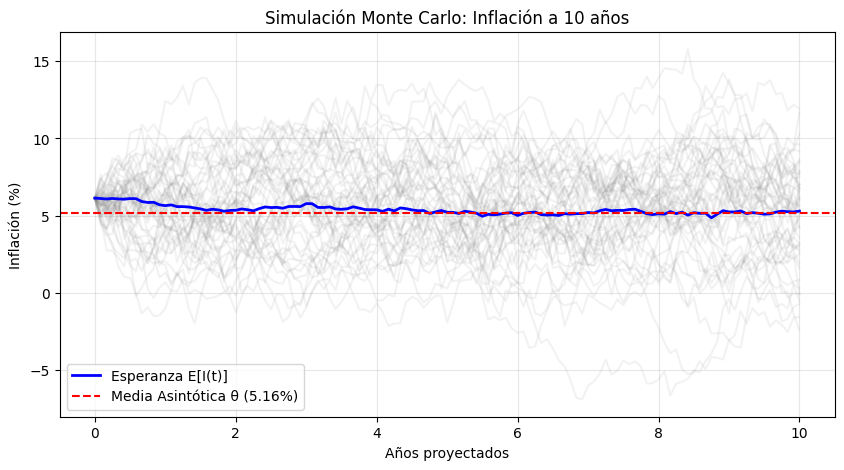

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.api as sm

df = pd.read_csv('inflation_history_colombia.csv', sep=';', decimal=',', parse_dates=['DateTime'])
df = df.set_index('DateTime')
df_2016 = df[df.index >= '2016-01-01'].copy()
ts = df_2016['Inflación total anual'].dropna() / 100.0

ts_semestral = ts[ts.index.month.isin([6, 12])]

Y = ts_semestral.values[1:]
X = ts_semestral.values[:-1]
X = sm.add_constant(X)

model = sm.OLS(Y, X).fit()
alpha, beta = model.params
var_eps = model.mse_resid
dt = 0.5

a = -np.log(beta) / dt
sigma = np.sqrt((2 * a * var_eps) / (1 - beta**2))
theta = alpha / (1 - beta)

# 2. Configuración del espacio de simulación
T = 10 
dt_sim = 1/12  
N = int(T / dt_sim) 
M = 500

# 3. Inicialización matricial y condición de frontera
paths = np.zeros((M, N + 1))
I0 = Y[-1]  
paths[:, 0] = I0

# 4. Integración estocástica (Euler-Maruyama)
np.random.seed(42)
for t in range(1, N + 1):
    Z = np.random.standard_normal(M)
    drift = a * (theta - paths[:, t - 1]) * dt_sim
    diffusion = sigma * np.sqrt(dt_sim) * Z
    paths[:, t] = paths[:, t - 1] + drift + diffusion

# 5. Renderizado gráfico de las trayectorias
import matplotlib.pyplot as plt

time_axis = np.linspace(0, T, N + 1)
plt.figure(figsize=(10, 5))
plt.plot(time_axis, paths[:50, :].T * 100, color='gray', alpha=0.1) 
plt.plot(time_axis, np.median(paths, axis=0) * 100, color='blue', linewidth=2, label='Esperanza E[I(t)]')
plt.axhline(theta * 100, color='red', linestyle='--', label=f'Media Asintótica θ ({theta*100:.2f}%)')
plt.title('Simulación Monte Carlo: Inflación a 10 años')
plt.xlabel('Años proyectados')
plt.ylabel('Inflación (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [2]:
np.mean(paths, axis=0)

array([0.0614    , 0.06120209, 0.06144618, 0.06113265, 0.06062342,
       0.05987503, 0.05917558, 0.05865869, 0.05856066, 0.05845885,
       0.0581044 , 0.05752773, 0.05721462, 0.05708121, 0.05741892,
       0.05746737, 0.05718998, 0.05723452, 0.05729769, 0.05705466,
       0.0571225 , 0.05658753, 0.05675098, 0.05605864, 0.05579706,
       0.05545067, 0.05541131, 0.05565546, 0.05534384, 0.05456838,
       0.0544925 , 0.05462542, 0.05433599, 0.05386799, 0.0540995 ,
       0.05353486, 0.05307004, 0.05310909, 0.0525175 , 0.05264779,
       0.05310104, 0.0532846 , 0.05342762, 0.05341   , 0.05343031,
       0.0535384 , 0.05369957, 0.05323585, 0.05273601, 0.05275006,
       0.05303556, 0.05296897, 0.05285609, 0.05301068, 0.05289897,
       0.0533125 , 0.05271584, 0.05235872, 0.05251526, 0.05235935,
       0.05273472, 0.05293548, 0.05301898, 0.05319796, 0.05326965,
       0.05351401, 0.05337755, 0.05349257, 0.05334486, 0.05338931,
       0.05308886, 0.05284193, 0.05231962, 0.05291863, 0.05280